# Expérience — Estimation du prix par RAG filtré

Dans ce notebook expérimental, nous testons une stratégie de prédiction différente des modèles de régression classiques : un **RAG filtré** (*Retrieval-Augmented Generation*). Pour estimer le prix d'une maison, nous retrouvons d'abord des ventes comparables dans les données d'entraînement, puis nous demandons à un grand modèle de langage (LLM) d'estimer le prix à partir de ces comparables, comme le ferait un évaluateur immobilier.

Cette expérience ne remplace pas les étapes 4 et 5 du travail. Elle servira de point de comparaison pour le modèle principal, choisi ultérieurement dans [le notebook de développement de la solution](../05_developpement_solution.ipynb).

La stratégie comporte trois parties :

1. **Indexation (une seule fois).** Chaque maison de l'entraînement est décrite par un court texte, transformé en vecteur (*embedding*) avec `sentence-transformers/all-MiniLM-L6-v2`, puis stockée dans une base vectorielle ChromaDB avec son prix et quelques métadonnées : `SalePrice`, `Neighborhood`, `BldgType`, `MSSubClass` et `GrLivArea`.
2. **Recherche filtrée avec repli.** Pour une maison à évaluer, nous cherchons les *k* = 5 maisons les plus proches en relâchant progressivement un filtre sur les métadonnées : même `MSSubClass` et même quartier, sinon même `MSSubClass` et même type de bâtiment, sinon même `MSSubClass`, sinon aucun filtre.
3. **Prompt et LLM.** Le modèle reçoit les cinq comparables et leur prix, puis la description de la maison cible. Il renvoie une réponse structurée : prix estimé, niveau de confiance et justification. Si la recherche échoue, il estime le prix sans comparables.

**Hypothèse testée.** Le filtre sur les métadonnées devrait faire la différence avec un RAG naïf. La similarité de texte seule peut ramener des maisons qui « se ressemblent » dans leur description, mais qui appartiennent à un autre marché, par exemple un duplex d'un quartier modeste pour une maison unifamiliale d'un quartier recherché. L'analyse exploratoire a montré que le quartier et le type de logement sont fortement associés au prix ([étape 3](../03_analyse_exploratoire.ipynb), sections 7.3 à 7.5). Nous comparons donc systématiquement la recherche filtrée à une recherche naïve, sans filtre.

**Coût.** La section 5 appelle l'API OpenAI une fois par maison évaluée, soit 292 appels pour toute la validation. Les réponses sont conservées dans un cache local : une nouvelle exécution ne repaie pas les appels déjà faits, tant que le modèle et les prompts ne changent pas.

## 1. Configuration

Les paramètres de l'expérience sont regroupés ci-dessous. Pour un premier essai à faible coût, donner à `N_LLM` une petite valeur, par exemple 20 : l'évaluation porte alors sur un échantillon de la validation, et les méthodes sans LLM sont comparées sur les mêmes maisons.

La clé de l'API doit être définie dans la variable d'environnement `OPENAI_API_KEY`, ou dans un fichier `.env` à la racine du dépôt (ignoré par Git) contenant la ligne `OPENAI_API_KEY=...`. Sans clé, le notebook s'exécute quand même : seules les méthodes sans LLM sont évaluées.

In [1]:
import hashlib
import json
import os
import threading
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from typing import Literal

import chromadb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from IPython.display import display
from openai import OpenAI
from pydantic import BaseModel, Field
from sentence_transformers import SentenceTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# Repérer la racine depuis le dossier courant ou l'un de ses parents.
current = Path.cwd().resolve()
root = next(
    (path for path in (current, *current.parents) if (path / "pyproject.toml").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dépôt MAP6014.")
data_dir = root / "data"

# Partition
RANDOM_STATE = 42
VALIDATION_SIZE = 0.20

# Recherche
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
K = 5

# LLM
LLM_MODEL = "gpt-6-luna"
REASONING_EFFORT = "medium"
MAX_WORKERS = 8      # appels simultanés à l'API
N_LLM = None         # None : toute la validation; un entier (ex. 20) pour un essai
RUN_NAIVE_LLM = False  # True : évaluer aussi le LLM avec un RAG naïf (double le coût)

# Fichiers locaux, ignorés par Git car situés dans data/
chroma_dir = data_dir / "chroma_ames"
cache_path = data_dir / "cache_rag" / "llm_predictions.jsonl"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100


def format_dollars(value):
    """Afficher un montant en dollars avec une espace comme séparateur de milliers."""
    return f"{value:,.0f} $".replace(",", " ")

c:\Users\tom_9\Projets\MAP6014---Travail-Final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Partition entraînement / validation

Nous séparons `train.csv` en **80 % pour l'entraînement** et **20 % pour la validation**, avec une graine fixe. Seules les maisons d'entraînement sont indexées : les maisons de validation ne peuvent donc jamais se retrouver parmi leurs propres comparables, et leur prix n'est jamais montré au modèle. `test.csv`, qui ne contient pas de prix, sera utilisé plus tard pour une soumission Kaggle.

In [2]:
read_options = {"na_values": ["NA"], "keep_default_na": False}
train_full = pd.read_csv(data_dir / "train.csv", **read_options)
test = pd.read_csv(data_dir / "test.csv", **read_options)
assert train_full.shape == (1460, 81) and test.shape == (1459, 80)

train_part, valid_part = train_test_split(
    train_full, test_size=VALIDATION_SIZE, random_state=RANDOM_STATE
)
train_part = train_part.reset_index(drop=True)
valid_part = valid_part.reset_index(drop=True)
assert not set(train_part["Id"]) & set(valid_part["Id"])

display(pd.DataFrame({
    "Partition": ["Entraînement (indexé)", "Validation (évaluée)", "test.csv (plus tard)"],
    "Maisons": [len(train_part), len(valid_part), len(test)],
    "Prix médian": [format_dollars(train_part["SalePrice"].median()),
                    format_dollars(valid_part["SalePrice"].median()), "inconnu"],
}))

,Partition,Maisons,Prix médian
0,Entraînement (indexé),1168,165 000 $
1,Validation (évaluée),292,154 150 $
2,test.csv (plus tard),1459,inconnu


Les deux partitions ont des prix médians proches, ce qui indique que la séparation aléatoire n'a pas créé de déséquilibre important. Avec 292 maisons, la validation reste petite : une différence de quelques pour cent entre deux méthodes peut venir du hasard de la partition (voir les limites, section 7).

## 3. Description textuelle et indexation

### Texte d'une propriété

Le même constructeur de texte sert pour l'indexation, la recherche et le prompt. Il décrit chaque maison par 19 caractéristiques, choisies parmi les plus liées au prix dans l'analyse exploratoire, sous la forme `Variable=valeur`. **Le prix n'en fait jamais partie** : il est stocké séparément dans les métadonnées.

In [3]:
KEY_FEATURES = [
    "Neighborhood", "BldgType", "HouseStyle", "OverallQual", "OverallCond", "YearBuilt",
    "YearRemodAdd", "GrLivArea", "TotalBsmtSF", "LotArea", "GarageCars", "FullBath",
    "BedroomAbvGr", "KitchenQual", "ExterQual", "Fireplaces", "PoolArea", "SaleCondition",
    "YrSold",
]
assert "SalePrice" not in KEY_FEATURES


def build_property_text(row):
    """Décrire une maison par « Variable=valeur », en omettant les valeurs absentes."""
    parts = []
    for column in KEY_FEATURES:
        value = row[column]
        if pd.isna(value):
            continue
        if isinstance(value, float) and value.is_integer():
            value = int(value)
        parts.append(f"{column}={value}")
    return "; ".join(parts)


print(build_property_text(valid_part.iloc[0]))

Neighborhood=Sawyer; BldgType=1Fam; HouseStyle=1Story; OverallQual=6; OverallCond=8; YearBuilt=1963; YearRemodAdd=2003; GrLivArea=1068; TotalBsmtSF=1059; LotArea=8414; GarageCars=1; FullBath=1; BedroomAbvGr=3; KitchenQual=TA; ExterQual=TA; Fireplaces=0; PoolArea=0; SaleCondition=Normal; YrSold=2006


### Indexation dans ChromaDB

Nous encodons les textes avec `all-MiniLM-L6-v2`, puis nous les stockons dans une collection ChromaDB persistante, dans `data/chroma_ames/`. Le nom de la collection dépend des identifiants de l'entraînement : si la partition change, une nouvelle collection est créée, ce qui évite de chercher dans un index contenant des maisons de validation. Si la collection existe déjà et est complète, l'indexation n'est pas refaite.

Les vecteurs sont normalisés : la distance euclidienne utilisée par ChromaDB classe alors les voisins dans le même ordre que la similarité cosinus.

In [4]:
encoder = SentenceTransformer(EMBEDDING_MODEL)
chroma_client = chromadb.PersistentClient(path=str(chroma_dir))

split_signature = hashlib.sha256(
    ",".join(map(str, sorted(train_part["Id"]))).encode()
).hexdigest()[:12]
collection_name = f"ames_train_{split_signature}"
collection = chroma_client.get_or_create_collection(collection_name)

if collection.count() != len(train_part):
    chroma_client.delete_collection(collection_name)
    collection = chroma_client.create_collection(collection_name)
    documents = [build_property_text(row) for _, row in train_part.iterrows()]
    embeddings = encoder.encode(documents, batch_size=64, normalize_embeddings=True)
    collection.add(
        ids=train_part["Id"].astype(str).tolist(),
        documents=documents,
        embeddings=embeddings.tolist(),
        metadatas=[
            {
                "SalePrice": float(row["SalePrice"]),
                "Neighborhood": str(row["Neighborhood"]),
                "BldgType": str(row["BldgType"]),
                "MSSubClass": int(row["MSSubClass"]),
                "GrLivArea": float(row["GrLivArea"]),
            }
            for _, row in train_part.iterrows()
        ],
    )
    print(f"Collection {collection_name} créée : {collection.count()} maisons indexées.")
else:
    print(f"Collection {collection_name} réutilisée : {collection.count()} maisons.")
assert collection.count() == len(train_part)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2807.34it/s]


Collection ames_train_f951173f94ce réutilisée : 1168 maisons.


## 4. Recherche filtrée avec repli

`build_find_similar` construit la fonction de recherche. La maison cible est encodée avec le même constructeur de texte, puis nous demandons à ChromaDB les *k* voisins les plus proches en appliquant le premier filtre. Si moins de *k* maisons satisfont ce filtre, nous passons au filtre suivant :

| Niveau | Filtre sur les métadonnées |
|---|---|
| 1 | même `MSSubClass` et même `Neighborhood` |
| 2 | même `MSSubClass` et même `BldgType` |
| 3 | même `MSSubClass` |
| 4 | aucun filtre |

Le paramètre `exclude_id` retire une maison de ses propres résultats. Il n'est pas nécessaire ici, puisque la validation n'est pas indexée, mais il permettra une évaluation « une maison à la fois » sur l'entraînement. Le RAG naïf utilise la même fonction avec le seul niveau « aucun filtre ».

In [5]:
FILTER_LEVELS = [
    ("MSSubClass + Neighborhood", lambda row: {"$and": [
        {"MSSubClass": int(row["MSSubClass"])}, {"Neighborhood": str(row["Neighborhood"])},
    ]}),
    ("MSSubClass + BldgType", lambda row: {"$and": [
        {"MSSubClass": int(row["MSSubClass"])}, {"BldgType": str(row["BldgType"])},
    ]}),
    ("MSSubClass", lambda row: {"MSSubClass": int(row["MSSubClass"])}),
    ("Aucun filtre", lambda row: None),
]


def build_find_similar(collection, encoder, k=K, levels=FILTER_LEVELS):
    """Créer une fonction qui renvoie (comparables, niveau de filtre utilisé)."""

    def find_similar(row, exclude_id=None):
        query = encoder.encode([build_property_text(row)], normalize_embeddings=True)
        comparables, level_name = [], None
        for level_name, make_filter in levels:
            result = collection.query(
                query_embeddings=query.tolist(),
                n_results=k + 1,  # une de plus, au cas où exclude_id serait retourné
                where=make_filter(row),
                include=["documents", "metadatas", "distances"],
            )
            comparables = [
                {"Id": int(item_id), "text": document, "price": metadata["SalePrice"],
                 "Neighborhood": metadata["Neighborhood"], "distance": distance}
                for item_id, document, metadata, distance in zip(
                    result["ids"][0], result["documents"][0],
                    result["metadatas"][0], result["distances"][0],
                )
                if item_id != str(exclude_id)
            ][:k]
            if len(comparables) >= k:
                break
        return comparables, level_name

    return find_similar


find_similar = build_find_similar(collection, encoder)
find_similar_naive = build_find_similar(
    collection, encoder, levels=[("Aucun filtre", lambda row: None)]
)


def retrieve_all(frame, search):
    """Chercher les comparables de chaque maison; une erreur donne une liste vide."""
    retrieved = {}
    for _, row in frame.iterrows():
        try:
            comparables, level_name = search(row)
        except Exception as error:  # le repli sans RAG sera utilisé
            comparables, level_name = [], f"Échec ({type(error).__name__})"
        retrieved[int(row["Id"])] = {"comparables": comparables, "level": level_name}
    return retrieved


retrieved_filtered = retrieve_all(valid_part, find_similar)
retrieved_naive = retrieve_all(valid_part, find_similar_naive)

example = valid_part.iloc[0]
example_comparables = retrieved_filtered[int(example["Id"])]
print("Cible :", build_property_text(example))
print("Niveau de filtre :", example_comparables["level"])
display(pd.DataFrame(example_comparables["comparables"])[["Id", "Neighborhood", "price", "distance"]])

Cible : Neighborhood=Sawyer; BldgType=1Fam; HouseStyle=1Story; OverallQual=6; OverallCond=8; YearBuilt=1963; YearRemodAdd=2003; GrLivArea=1068; TotalBsmtSF=1059; LotArea=8414; GarageCars=1; FullBath=1; BedroomAbvGr=3; KitchenQual=TA; ExterQual=TA; Fireplaces=0; PoolArea=0; SaleCondition=Normal; YrSold=2006
Niveau de filtre : MSSubClass + Neighborhood


,Id,Neighborhood,price,distance
0,476,Sawyer,132500.0,0.006094
1,1200,Sawyer,148000.0,0.006516
2,669,Sawyer,168000.0,0.010478
3,1082,Sawyer,133000.0,0.010515
4,900,Sawyer,135000.0,0.011600


### Niveaux de filtre utilisés et qualité des comparables

Avant d'appeler le LLM, nous examinons gratuitement deux questions : à quel niveau de filtre la recherche s'arrête-t-elle, et les comparables trouvés sont-ils déjà de bons indicateurs du prix? Pour la seconde, nous utilisons une **référence sans LLM** : le prix médian des cinq comparables. Si le LLM n'améliore pas cette référence, il n'apporte rien de plus que la recherche.

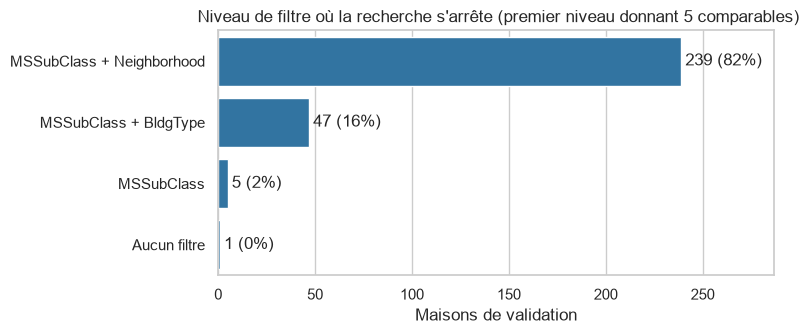

Comparables du même quartier : 89.7 % (RAG filtré) contre 98.0 % (RAG naïf)


In [7]:
level_order = [name for name, _ in FILTER_LEVELS]
levels_used = pd.Series(
    [item["level"] for item in retrieved_filtered.values()], name="Niveau"
)
level_counts = levels_used.value_counts().reindex(
    level_order + sorted(set(levels_used) - set(level_order)), fill_value=0
)

# Part des comparables situés dans le même quartier que la maison cible.
valid_by_id = valid_part.set_index("Id")


def same_neighborhood_share(retrieved):
    shares = [
        np.mean([c["Neighborhood"] == valid_by_id.loc[house_id, "Neighborhood"]
                 for c in item["comparables"]])
        for house_id, item in retrieved.items() if item["comparables"]
    ]
    return float(np.mean(shares) * 100)


fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=level_counts.values, y=level_counts.index, color="tab:blue", ax=ax)
for position, count in enumerate(level_counts.values):
    ax.text(count + 2, position, f"{count} ({count / len(valid_part):.0%})", va="center")
ax.set_title(" Niveau de filtre où la recherche s'arrête (premier niveau donnant 5 comparables)")
ax.set_xlabel("Maisons de validation")
ax.set_ylabel("")
ax.set_xlim(0, level_counts.max() * 1.2)
plt.tight_layout()
plt.show()

print(f"Comparables du même quartier : {same_neighborhood_share(retrieved_filtered):.1f} % "
      f"(RAG filtré) contre {same_neighborhood_share(retrieved_naive):.1f} % (RAG naïf)")

**Question.** Le filtre le plus strict trouve-t-il assez de comparables, et change-t-il réellement les maisons retrouvées?

**Observation.** Lors de notre exécution, le filtre le plus strict (même `MSSubClass` et même quartier) suffit pour **239 maisons sur 292 (82 %)**. Il faut relâcher le quartier pour 47 maisons (16 %), et seulement 6 maisons descendent aux niveaux 3 ou 4. Contrairement à notre hypothèse, le RAG naïf retrouve déjà des comparables du même quartier dans **98,0 %** des cas, contre 89,7 % pour le RAG filtré.

**Interprétation.** Le quartier est la première information du texte encodé (`Neighborhood=...`) : l'embedding le capte fortement, et la recherche naïve reste presque toujours dans le bon marché local. Le filtre ajoute surtout la contrainte du même `MSSubClass`. Au niveau 2, il abandonne le quartier pour conserver `MSSubClass` et `BldgType` : c'est ce qui fait baisser la part de comparables du même quartier.

**Conséquence.** L'ordre des niveaux de repli mérite d'être testé. Une variante qui garde le quartier au niveau 2 (`Neighborhood + BldgType`, puis `Neighborhood` seul) conserverait le marché local. La section 6 mesure l'effet de ces choix sur les erreurs.

## 5. Prompt et LLM

### Prompts

Le *system prompt* donne au modèle le rôle d'un expert en évaluation immobilière à Ames entre 2006 et 2010, et rappelle les facteurs de prix mis en évidence par l'analyse exploratoire. Le *user prompt* présente les cinq comparables avec leur prix, puis la maison cible. Les prompts sont rédigés en anglais, comme les noms des variables et les codes du jeu de données.

In [10]:
SYSTEM_PROMPT = """You are an expert residential real estate appraiser for Ames, Iowa, \
specialized in home sales from 2006 to 2010. Estimate the sale price in US dollars of the \
target property from its characteristics and, when provided, from comparable sales.

Key value factors:
- Location (Neighborhood) and dwelling type (BldgType, HouseStyle).
- Overall material and finish quality (OverallQual) and overall condition (OverallCond).
- Above-ground living area (GrLivArea), basement area (TotalBsmtSF) and lot area (LotArea).
- Age and renovation (YearBuilt, YearRemodAdd) relative to the sale year (YrSold).
- Garage capacity, bathrooms, bedrooms, fireplaces, kitchen and exterior quality.
- Sale condition: Partial (new construction) and Abnorml (foreclosure, short sale) \
sales often deviate from typical market prices.

Adjust the comparable prices for the differences with the target property instead of \
averaging them. Report your confidence as low, medium or high and briefly explain the \
main adjustments."""


def build_user_prompt(row, comparables):
    """Prompt avec comparables (RAG) ou, si la liste est vide, sans comparables."""
    target = build_property_text(row)
    if not comparables:
        return f"Estimate the price for this property: {target}"
    blocks = [
        f"Similar property {i}:\n{c['text']}\nPrice: ${c['price']:,.0f}"
        for i, c in enumerate(comparables, start=1)
    ]
    return "\n\n".join(blocks) + f"\n\nNow estimate the price for this property:\n{target}"


class PricePrediction(BaseModel):
    predicted_price: float = Field(gt=0, description="Estimated sale price in US dollars")
    confidence: Literal["low", "medium", "high"]
    reasoning: str = Field(description="Short justification of the main adjustments")


print(SYSTEM_PROMPT)
print("\n" + "-" * 80 + "\n")
print(build_user_prompt(example, example_comparables["comparables"]))

You are an expert residential real estate appraiser for Ames, Iowa, specialized in home sales from 2006 to 2010. Estimate the sale price in US dollars of the target property from its characteristics and, when provided, from comparable sales.

Key value factors:
- Location (Neighborhood) and dwelling type (BldgType, HouseStyle).
- Overall material and finish quality (OverallQual) and overall condition (OverallCond).
- Above-ground living area (GrLivArea), basement area (TotalBsmtSF) and lot area (LotArea).
- Age and renovation (YearBuilt, YearRemodAdd) relative to the sale year (YrSold).
- Garage capacity, bathrooms, bedrooms, fireplaces, kitchen and exterior quality.
- Sale condition: Partial (new construction) and Abnorml (foreclosure, short sale) sales often deviate from typical market prices.

Adjust the comparable prices for the differences with the target property instead of averaging them. Report your confidence as low, medium or high and briefly explain the main adjustments.

--

### Appels au modèle et cache

Chaque appel utilise l'API *Responses* d'OpenAI avec une **sortie structurée** : le SDK convertit la classe Pydantic `PricePrediction` en schéma JSON et renvoie un objet validé. Les réponses sont ajoutées au fichier `data/cache_rag/llm_predictions.jsonl`. La clé du cache combine le modèle, l'effort de raisonnement et les deux prompts : modifier l'un d'eux déclenche de nouveaux appels, tandis qu'une réexécution identique relit le cache.

Les appels sont faits en parallèle (`MAX_WORKERS`). Une erreur sur une maison (limite de débit persistante, réponse invalide) est enregistrée sans interrompre les autres; ces maisons sont exclues de l'évaluation et comptées dans le bilan.

Pendant l'exécution, une barre de progression affiche la RMSE des logarithmes cumulée et le nombre d'erreurs. Chaque maison terminée est aussi affichée par l'écart entre le prix prédit et le prix réel : en vert sous 10 %, en jaune sous 20 %, en rouge au-delà.

In [11]:
load_dotenv(root / ".env")
LLM_AVAILABLE = bool(os.environ.get("OPENAI_API_KEY"))
if not LLM_AVAILABLE:
    print("OPENAI_API_KEY absente : les sections LLM sont ignorées, "
          "seules les méthodes sans LLM seront évaluées.")
else:
    llm_client = OpenAI(max_retries=5)

cache_path.parent.mkdir(parents=True, exist_ok=True)
cache = {}
if cache_path.exists():
    for line in cache_path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            entry = json.loads(line)
            cache[entry["key"]] = entry
cache_lock = threading.Lock()


def cache_key(user_prompt):
    payload = json.dumps([LLM_MODEL, REASONING_EFFORT, SYSTEM_PROMPT, user_prompt])
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def predict_price(house_id, row, comparables):
    """Prédire un prix avec le LLM; repli sans RAG si aucun comparable."""
    user_prompt = build_user_prompt(row, comparables)
    key = cache_key(user_prompt)
    if key in cache:
        return cache[key]

    start = time.perf_counter()
    response = llm_client.responses.parse(
        model=LLM_MODEL,
        reasoning={"effort": REASONING_EFFORT},
        instructions=SYSTEM_PROMPT,
        input=user_prompt,
        text_format=PricePrediction,
    )
    parsed = response.output_parsed
    if parsed is None:
        raise ValueError("Réponse sans sortie structurée (refus ou réponse incomplète).")
    entry = {
        "key": key,
        "Id": int(house_id),
        "with_rag": bool(comparables),
        **parsed.model_dump(),
        "input_tokens": response.usage.input_tokens,
        "output_tokens": response.usage.output_tokens,
        "seconds": round(time.perf_counter() - start, 2),
    }
    with cache_lock:
        cache[key] = entry
        with cache_path.open("a", encoding="utf-8") as file:
            file.write(json.dumps(entry, ensure_ascii=False) + "\n")
    return entry


GREEN, YELLOW, RED, RESET = "\033[92m", "\033[93m", "\033[91m", "\033[0m"


def gap_color(gap):
    """Vert : écart < 10 %; jaune : < 20 %; rouge : au-delà."""
    if abs(gap) < 0.10:
        return GREEN
    if abs(gap) < 0.20:
        return YELLOW
    return RED


def run_llm(frame, retrieved, label):
    """Prédire toutes les maisons de frame en parallèle; renvoie un DataFrame.

    Pendant l'exécution, une barre de progression indique la RMSE des logarithmes
    cumulée, et chaque maison terminée est affichée par son écart au prix réel.
    """
    rows, errors, squared_log_errors = [], [], []
    actual_prices = frame.set_index("Id")["SalePrice"]
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
        futures = {
            pool.submit(predict_price, int(row["Id"]), row,
                        retrieved[int(row["Id"])]["comparables"]): int(row["Id"])
            for _, row in frame.iterrows()
        }
        progress = tqdm(as_completed(futures), total=len(futures), desc=label)
        for future in progress:
            house_id = futures[future]
            try:
                entry = future.result()
            except Exception as error:
                errors.append({"Id": house_id, "Erreur": f"{type(error).__name__}: {error}"})
                print(f"{RED}échec{RESET} ", end="")
            else:
                rows.append({**entry, "Id": house_id})
                ratio = entry["predicted_price"] / actual_prices[house_id]
                squared_log_errors.append(np.log(ratio) ** 2)
                print(f"{gap_color(ratio - 1)}{ratio - 1:+.0%}{RESET} ", end="")
            progress.set_postfix({
                "RMSE log": f"{np.sqrt(np.mean(squared_log_errors)):.3f}"
                if squared_log_errors else "-",
                "erreurs": len(errors),
            })
    print(f"\n{label} : {len(rows)} prédictions, {len(errors)} erreurs.")
    return pd.DataFrame(rows), pd.DataFrame(errors)

### Test sur une maison

Avant de lancer toute la validation, nous vérifions la chaîne complète sur **une seule maison** : recherche des comparables, prompt, appel au LLM et lecture de la réponse structurée. Ce test coûte un seul appel. Sa réponse est conservée dans le cache : la même maison ne sera pas facturée de nouveau lors de l'évaluation complète.

Pour tester une autre maison, changer `TEST_INDEX` (position dans la validation).

In [12]:
TEST_INDEX = 0

if not LLM_AVAILABLE:
    print("OPENAI_API_KEY absente : test ignoré.")
else:
    test_row = valid_part.iloc[TEST_INDEX]
    test_id = int(test_row["Id"])
    test_retrieval = retrieved_filtered[test_id]
    test_entry = predict_price(test_id, test_row, test_retrieval["comparables"])

    actual = test_row["SalePrice"]
    predicted = test_entry["predicted_price"]
    comparables_median_price = np.median([c["price"] for c in test_retrieval["comparables"]])

    print("Maison :", build_property_text(test_row))
    print(f"Niveau de filtre : {test_retrieval['level']}\n")
    display(pd.DataFrame({
        "Prix": [actual, predicted, comparables_median_price],
        "Écart au prix réel": [0.0, predicted / actual - 1, comparables_median_price / actual - 1],
    }, index=["Prix réel", "LLM + RAG filtré", "Médiane des comparables"])
        .style.format({"Prix": format_dollars, "Écart au prix réel": "{:+.1%}"}))
    print(f"Erreur log : {abs(np.log(predicted) - np.log(actual)):.4f}")
    print(f"Confiance : {test_entry['confidence']}")
    print(f"Justification : {test_entry['reasoning']}\n")
    print(f"Jetons : {test_entry['input_tokens']:,} en entrée, "
          f"{test_entry['output_tokens']:,} en sortie | durée : {test_entry['seconds']} s")

Maison : Neighborhood=Sawyer; BldgType=1Fam; HouseStyle=1Story; OverallQual=6; OverallCond=8; YearBuilt=1963; YearRemodAdd=2003; GrLivArea=1068; TotalBsmtSF=1059; LotArea=8414; GarageCars=1; FullBath=1; BedroomAbvGr=3; KitchenQual=TA; ExterQual=TA; Fireplaces=0; PoolArea=0; SaleCondition=Normal; YrSold=2006
Niveau de filtre : MSSubClass + Neighborhood



,Prix,Écart au prix réel
Prix réel,154 500 $,+0.0%
LLM + RAG filtré,143 000 $,-7.4%
Médiane des comparables,135 000 $,-12.6%


Erreur log : 0.0773
Confiance : medium
Justification : The target is smaller than the stronger 2006 Sawyer comparables, but its OverallQual 6, OverallCond 8, and 2003 remodel warrant upward adjustments over the mostly less-updated homes. Its one-car garage and lack of a fireplace offset some of that advantage; the closest smaller 2006 sales support an estimate around $143,000.

Jetons : 1,049 en entrée, 498 en sortie | durée : 8.58 s


In [13]:
llm_frame = (
    valid_part if N_LLM is None
    else valid_part.sample(n=N_LLM, random_state=RANDOM_STATE)
)

llm_results, llm_errors = {}, {}
if LLM_AVAILABLE:
    strategies = {"LLM + RAG filtré": retrieved_filtered}
    if RUN_NAIVE_LLM:
        strategies["LLM + RAG naïf"] = retrieved_naive
    for label, retrieved in strategies.items():
        llm_results[label], llm_errors[label] = run_llm(llm_frame, retrieved, label)
        if not llm_errors[label].empty:
            display(llm_errors[label].head())

LLM + RAG filtré : 50/292 maisons traitées
LLM + RAG filtré : 100/292 maisons traitées
LLM + RAG filtré : 150/292 maisons traitées
LLM + RAG filtré : 200/292 maisons traitées
LLM + RAG filtré : 250/292 maisons traitées
LLM + RAG filtré : 292/292 maisons traitées
LLM + RAG filtré : 292 prédictions, 0 erreurs.


## 6. Évaluation

### Métriques

La métrique principale est celle de Kaggle, la **RMSE des logarithmes** (logarithme naturel), présentée à l'étape 2 :

$$
\operatorname{RMSE}_{\log}
=
\sqrt{\frac{1}{n}\sum_{i=1}^{n}
\left(\log(\widehat{y}_i)-\log(y_i)\right)^2}.
$$

Nous ajoutons la RMSE et la MAE en dollars ainsi que le R², calculé sur les prix en dollars. Nous comparons quatre méthodes, **sur les mêmes maisons** :

| Méthode | Description |
|---|---|
| Médiane globale | Prix médian de l'entraînement pour toutes les maisons : référence minimale. |
| Médiane des comparables, RAG naïf | Prix médian des 5 voisins trouvés sans filtre, sans LLM. |
| Médiane des comparables, RAG filtré | Prix médian des 5 voisins trouvés avec le filtre et le repli, sans LLM. |
| LLM + RAG filtré | Prix estimé par le LLM à partir des 5 comparables filtrés. |

In [14]:
def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return {
        "RMSE log": np.sqrt(np.mean((np.log(y_pred) - np.log(y_true)) ** 2)),
        "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE ($)": mean_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred),
        "Maisons": len(y_true),
    }


def comparables_median(retrieved):
    return pd.Series({
        house_id: np.median([c["price"] for c in item["comparables"]])
        if item["comparables"] else np.nan
        for house_id, item in retrieved.items()
    })


predictions = pd.DataFrame({
    "Id": valid_part["Id"],
    "SalePrice": valid_part["SalePrice"],
    "Niveau": valid_part["Id"].map(lambda house_id: retrieved_filtered[house_id]["level"]),
    "Médiane globale": train_part["SalePrice"].median(),
    "Médiane des comparables, RAG naïf": valid_part["Id"].map(comparables_median(retrieved_naive)),
    "Médiane des comparables, RAG filtré": valid_part["Id"].map(comparables_median(retrieved_filtered)),
})
for label, frame in llm_results.items():
    if not frame.empty:
        indexed = frame.set_index("Id")
        predictions[label] = predictions["Id"].map(indexed["predicted_price"])
        predictions[f"{label} — confiance"] = predictions["Id"].map(indexed["confidence"])

methods = [column for column in predictions.columns
           if column not in {"Id", "SalePrice", "Niveau"} and "confiance" not in column]
# Comparer toutes les méthodes sur les maisons pour lesquelles chacune a une prédiction.
common = predictions.dropna(subset=methods)

results = pd.DataFrame(
    {method: regression_metrics(common["SalePrice"], common[method]) for method in methods}
).T.sort_values("RMSE log")
display(results.style.format({
    "RMSE log": "{:.4f}", "RMSE ($)": "{:,.0f}", "MAE ($)": "{:,.0f}", "R²": "{:.3f}",
    "Maisons": "{:.0f}",
}))

,RMSE log,RMSE ($),MAE ($),R²,Maisons
LLM + RAG filtré,0.1396,"27,754","18,119",0.900,292
"Médiane des comparables, RAG naïf",0.2284,"47,817","28,403",0.702,292
"Médiane des comparables, RAG filtré",0.2472,"51,730","30,664",0.651,292
Médiane globale,0.4323,"88,667","59,568",-0.025,292


**Interprétation des méthodes sans LLM.** Lors de notre exécution sur les 292 maisons de validation, la médiane globale obtient une RMSE des logarithmes de 0,432 (R² proche de 0) : c'est le niveau à battre. La médiane des comparables réduit fortement l'erreur, mais **le RAG naïf (0,228) fait mieux que le RAG filtré (0,247)**, avec une MAE de 28 403 $ contre 30 664 $. Le filtre, tel que défini, n'améliore donc pas la qualité des comparables. Le tableau suivant détaille l'erreur selon le niveau de filtre atteint.

**Interprétation du LLM.** À compléter après exécution : gain du LLM par rapport à la médiane des comparables filtrés. Pour situer ces valeurs, les modèles de régression bien ajustés obtiennent généralement une RMSE des logarithmes proche de 0,12 à 0,14 sur ce jeu de données.

In [15]:
squared_log_errors = pd.DataFrame({
    method: (np.log(common[method]) - np.log(common["SalePrice"])) ** 2
    for method in methods if method != "Médiane globale"
})
by_level = (
    squared_log_errors.groupby(common["Niveau"]).mean().pipe(np.sqrt)
    .reindex([level for level in level_order if level in set(common["Niveau"])])
    .round(3)
)
by_level.insert(0, "Maisons", common["Niveau"].value_counts())
by_level.columns = ["Maisons"] + [f"RMSE log — {name}" for name in by_level.columns[1:]]
display(by_level)

,Maisons,"RMSE log — Médiane des comparables, RAG naïf","RMSE log — Médiane des comparables, RAG filtré",RMSE log — LLM + RAG filtré
Niveau,,,,
MSSubClass + Neighborhood,239,0.199,0.210,0.124
MSSubClass + BldgType,47,0.334,0.384,0.199
MSSubClass,5,0.184,0.109,0.097
Aucun filtre,1,0.594,0.594,0.278


Lors de notre exécution, l'écart vient surtout du **niveau 2** (47 maisons) : en remplaçant le quartier par `BldgType`, le RAG filtré atteint une RMSE des logarithmes de 0,384, contre 0,334 pour les comparables naïfs des mêmes maisons. Au niveau 1, forcer le même `MSSubClass` donne aussi des comparables légèrement moins bons (0,210 contre 0,199), car le filtre écarte des maisons du même quartier dont la description est plus proche. Les niveaux 3 et 4 concernent trop peu de maisons pour conclure.

Ces résultats ne condamnent pas le filtrage : ils indiquent que **le quartier est le critère à protéger en priorité**, et que `MSSubClass` est trop restrictif comme premier critère. Il reste à vérifier si le LLM, qui ajuste les prix au lieu de prendre la médiane, profite davantage des comparables filtrés.

### Prédictions et prix réels

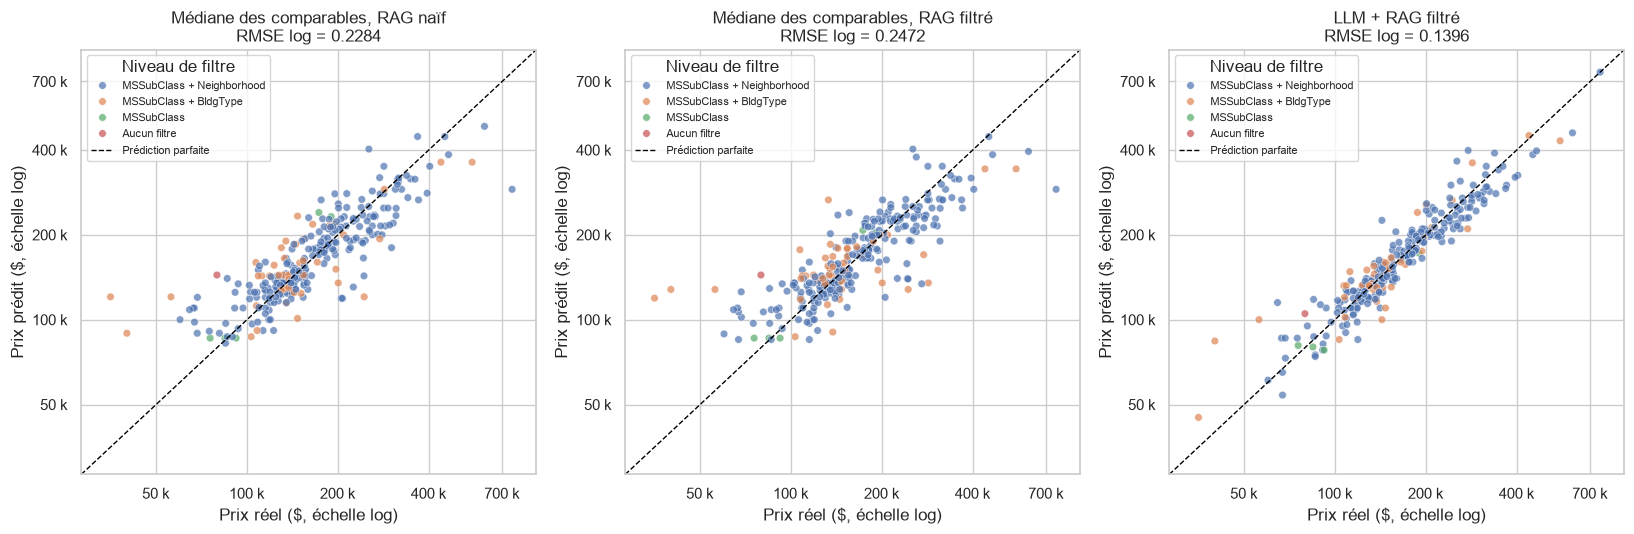

In [16]:
panels = [
    "Médiane des comparables, RAG naïf", "Médiane des comparables, RAG filtré",
] + [label for label in llm_results if label in common.columns]
ticks = [50_000, 100_000, 200_000, 400_000, 700_000]
tick_labels = [f"{tick // 1000} k" for tick in ticks]

fig, axes = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 5.5), squeeze=False)
limits = (common["SalePrice"].min() * 0.8, common["SalePrice"].max() * 1.2)
for ax, method in zip(axes[0], panels):
    sns.scatterplot(x=common["SalePrice"], y=common[method], hue=common["Niveau"],
                    hue_order=level_order, alpha=0.7, s=30, ax=ax)
    ax.plot(limits, limits, color="black", linestyle="--", linewidth=1, label="Prédiction parfaite")
    ax.set(xscale="log", yscale="log", xlim=limits, ylim=limits,
           xlabel="Prix réel ($, échelle log)", ylabel="Prix prédit ($, échelle log)")
    ax.set_xticks(ticks, tick_labels)
    ax.set_yticks(ticks, tick_labels)
    ax.minorticks_off()
    rmse_log = regression_metrics(common["SalePrice"], common[method])["RMSE log"]
    ax.set_title(f"{method}\nRMSE log = {rmse_log:.4f}")
    ax.legend(title="Niveau de filtre", fontsize=8)
plt.tight_layout()
plt.show()

**Question.** Les prédictions suivent-elles les prix réels sur toute l'échelle, et les erreurs dépendent-elles du niveau de filtre?

**Observation (méthodes sans LLM).** Les points suivent la diagonale, mais le nuage s'aplatit aux extrémités : les maisons de moins de 100 000 $ sont surestimées et les maisons de plus de 400 000 $ sont sous-estimées. Plusieurs des plus fortes surestimations concernent des maisons évaluées au niveau 2 (en orange).

**Interprétation.** Une médiane de comparables ramène les prix vers le centre de leur groupe : elle ne peut pas prédire un prix plus élevé que tous les comparables. C'est précisément ce qu'un LLM qui ajuste les prix selon les différences pourrait corriger.

**Observation et interprétation (LLM).** À compléter après exécution : les prédictions extrêmes sont-elles mieux placées que pour la médiane des comparables?

**Conséquence.** À compléter : si le LLM corrige surtout les maisons extrêmes, l'ajustement des comparables apporte de l'information; sinon, la recherche seule explique l'essentiel de la performance.

### Erreurs selon le niveau de filtre et la confiance déclarée

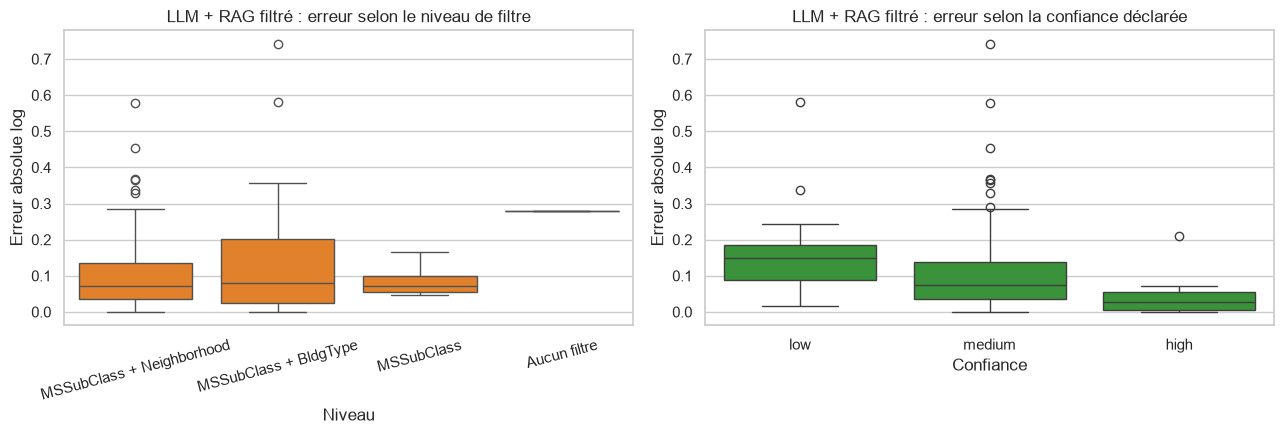

,count,median
Niveau,,
Aucun filtre,1,0.278
MSSubClass,5,0.070
MSSubClass + BldgType,47,0.081
MSSubClass + Neighborhood,239,0.072


,count,median
Confiance,,
high,14,0.028
low,22,0.148
medium,256,0.074


In [17]:
llm_labels = [label for label in llm_results if label in common.columns]
if not llm_labels:
    print("Aucune prédiction du LLM : section ignorée.")
else:
    label = llm_labels[0]
    errors = common.assign(**{
        "Erreur absolue log": (np.log(common[label]) - np.log(common["SalePrice"])).abs(),
        "Confiance": common[f"{label} — confiance"],
    })
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    sns.boxplot(data=errors, x="Niveau", y="Erreur absolue log",
                order=[level for level in level_order if level in set(errors["Niveau"])],
                color="tab:orange", ax=axes[0])
    axes[0].set_title(f"{label} : erreur selon le niveau de filtre")
    axes[0].tick_params(axis="x", rotation=15)
    sns.boxplot(data=errors, x="Confiance", y="Erreur absolue log",
                order=[c for c in ["low", "medium", "high"] if c in set(errors["Confiance"])],
                color="tab:green", ax=axes[1])
    axes[1].set_title(f"{label} : erreur selon la confiance déclarée")
    plt.tight_layout()
    plt.show()

    display(errors.groupby("Niveau")["Erreur absolue log"].agg(["count", "median"]).round(3))
    display(errors.groupby("Confiance")["Erreur absolue log"].agg(["count", "median"]).round(3))

**Question.** Les erreurs sont-elles plus grandes lorsque la recherche doit relâcher le filtre, et la confiance annoncée par le modèle est-elle informative?

**Observation et interprétation.** À compléter après exécution. Une confiance utile devrait correspondre à des erreurs plus faibles pour `high` que pour `low`. Si ce n'est pas le cas, la confiance n'est pas calibrée et ne doit pas servir à pondérer les prédictions.

### Plus grandes erreurs

Le tableau suivant présente les dix maisons dont l'erreur du LLM est la plus grande, avec la justification fournie par le modèle. Ces cas aident à comprendre si les erreurs viennent de mauvais comparables, d'un mauvais ajustement ou d'une vente particulière (par exemple `Partial` ou `Abnorml`).

In [18]:
if llm_labels:
    label = llm_labels[0]
    reasoning = llm_results[label].set_index("Id")["reasoning"]
    worst = (
        errors.assign(Écart=lambda frame: frame[label] / frame["SalePrice"] - 1)
        .sort_values("Erreur absolue log", ascending=False)
        .head(10)
    )
    worst = worst.merge(valid_part[["Id", "Neighborhood", "MSSubClass", "SaleCondition",
                                    "GrLivArea", "OverallQual"]], on="Id")
    worst["Justification"] = worst["Id"].map(reasoning)
    display(worst[["Id", "SalePrice", label, "Écart", "Niveau", "Confiance", "Neighborhood",
                   "MSSubClass", "SaleCondition", "GrLivArea", "OverallQual",
                   "Justification"]]
            .style.format({"SalePrice": "{:,.0f}", label: "{:,.0f}", "Écart": "{:+.0%}"}))

    usage = llm_results[label]
    print(f"Jetons d'entrée : {usage['input_tokens'].sum():,} | "
          f"jetons de sortie (raisonnement inclus) : {usage['output_tokens'].sum():,} | "
          f"durée médiane d'un appel : {usage['seconds'].median():.1f} s")

,Id,SalePrice,LLM + RAG filtré,Écart,Niveau,Confiance,Neighborhood,MSSubClass,SaleCondition,GrLivArea,OverallQual,Justification
0,31,"40,000","84,000",+110%,MSSubClass + BldgType,medium,IDOTRR,70,Normal,1317,4,"The closest match is the $78,000 IDOTRR sale: the target has more living area and a larger lot, but lower quality and condition. The other IDOTRR comparable sold for more but had substantially better condition and a recent remodel; accounting for those differences supports an estimate in the low-to-mid $80,000s."
1,813,"55,993","100,000",+79%,MSSubClass + BldgType,low,IDOTRR,20,Alloca,1044,5,"The target is similar in size and quality to the $128,000 NAmes sale, but its smaller basement, IDOTRR location, and fair kitchen and exterior warrant substantial downward adjustments. Its two-car garage helps offset some of that difference. The unusual Alloca sale condition adds uncertainty."
2,1433,"64,500","115,000",+78%,MSSubClass + Neighborhood,medium,OldTown,30,Normal,968,4,"The target’s 968 sq ft living area and OldTown location are close to the most relevant comparables. Its 2007 renovation, better condition than the low-condition sales, two bathrooms, and 10,800 sq ft lot support an upward adjustment; the limited basement area, one-car garage, and lower overall quality offset some of that. The larger, better-conditioned 2006 sale at $120,000 provides an upper reference, while the smaller and weaker sales support a lower bound."
3,589,"143,000","225,000",+57%,MSSubClass + Neighborhood,medium,ClearCr,20,Partial,1473,5,"The estimate is anchored by the $190,000–$235,000 Clear Creek sales with similar size and modest bedroom/bath counts. The target’s strong condition, 2003 remodel, excellent kitchen, larger lot, and two fireplaces add value; its smaller living area and single-car garage offset some of that premium. The unusual Partial sale condition adds uncertainty, so it is treated as a modest rather than decisive adjustment."
4,262,"276,000","398,500",+44%,MSSubClass + Neighborhood,medium,CollgCr,60,Partial,2574,8,"The target most closely matches the two larger 2007 CollgCr new-construction sales. Relative to the $383,970 comparable, its higher OverallQual and larger basement offset its slightly smaller living area and one fewer bedroom. Relative to the $424,870 comparable, its smaller living area and one fewer full bath are partly offset by its Excellent kitchen and slightly larger basement. The smaller comparables are less applicable; the estimate reflects the premium and variability of Partial new-construction sales."
5,582,"253,293","365,000",+44%,MSSubClass + Neighborhood,medium,NridgHt,20,Partial,2042,8,"The closest lower-quality new-construction comparable sold for $318,000, but it is 348 sq ft smaller and has a Good rather than Excellent kitchen. Adjusting upward for the target’s larger living area, superior kitchen, and 2009 timing suggests about $365,000. The higher-quality comparables support the area’s price level but warrant downward adjustment for the target’s OverallQual of 8; the unusually high normal-condition sale is less directly comparable to this Partial sale."
6,681,"143,000","100,000",-30%,MSSubClass + BldgType,medium,SawyerW,120,Normal,923,6,"Similar property 2 is an exceptionally close match: same neighborhood, age, quality, garage, bathrooms, bedrooms, fireplace, and 2010 sale year, with only 5 fewer square feet and a slightly smaller lot. Its $99,500 sale supports an estimate near $100,000; the larger, higher-finish comparables are not directly comparable."
7,1429,"119,000","85,000",-29%,MSSubClass + Neighborhood,low,OldTown,30,Abnorml,804,5,"The closest same-year comparable sold for $80,000, but the target has better condition and kitchen quality, a more recent remodel, slightly more living area, a larger lot, and two fireplaces, supporting a higher typical-market value. I apply a substantial discount for the Abnorml sale condition, leaving an estimate near $85,000."
8,1050,"84,900","118,000",+39%

Jetons d'entrée : 308,916 | jetons de sortie (raisonnement inclus) : 158,747 | durée médiane d'un appel : 7.5 s


**Interprétation.** À compléter après exécution.

## 7. Limites et pistes

- **Contamination possible.** Le jeu de données d'Ames et la compétition Kaggle sont publics depuis plusieurs années. Le LLM a peut-être vu ces ventes pendant son entraînement, ce qui pourrait rendre ses estimations meilleures que pour de vraies maisons inconnues. Un test serait de comparer ses erreurs sans comparables (prompt de repli) avec celles d'un modèle de régression simple : des erreurs anormalement faibles sans aucun contexte seraient un signal d'alerte.
- **Une seule partition de validation.** Avec 292 maisons, l'écart entre deux méthodes peut dépendre de la partition. Une validation croisée serait plus fiable, mais multiplierait le coût des appels.
- **Résultats non déterministes.** Deux exécutions du même prompt peuvent donner des prix différents. Le cache fige les réponses d'une exécution, mais la variabilité n'est pas mesurée.
- **Ordre des filtres.** La recherche naïve garde déjà le quartier dans 98 % des cas, et le filtre actuel l'abandonne au niveau 2. Variantes à comparer : `Neighborhood + BldgType`, puis `Neighborhood` seul, puis `MSSubClass`; ou encore un filtre sur la surface habitable.
- **Embeddings et nombres.** `all-MiniLM-L6-v2` est entraîné sur du langage naturel; il représente mal la proximité entre valeurs numériques (`GrLivArea=1500` et `GrLivArea=1520`). Les filtres sur les métadonnées compensent en partie cette limite; un filtre sur la surface (±20 %, comme dans le pseudo-code d'origine) serait une variante à tester.
- **Coût et durée.** Chaque prédiction exige un appel avec raisonnement, contrairement à un modèle de régression entraîné une seule fois.
- **Prédiction de `test.csv`.** Pour la soumission Kaggle, il faudra indexer les 1 460 maisons de `train.csv`, puis prédire les 1 459 maisons de `test.csv` avec les mêmes paramètres, sans les réajuster d'après le classement public.

### Fiche de l'expérience

À remplir après chaque exécution complète : commit, date, `RANDOM_STATE`, `K`, modèle d'embedding, `LLM_MODEL`, `REASONING_EFFORT`, `N_LLM`, nombre d'erreurs, métriques du tableau de la section 6 et coût approximatif.

## Références

- [Étape 2 — Présentation du problème](../02_presentation_probleme.ipynb), pour la métrique de Kaggle.
- [Étape 3 — Analyse exploratoire](../03_analyse_exploratoire.ipynb), pour le choix des caractéristiques et des filtres.
- [sentence-transformers/all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), modèle d'embedding.
- [Documentation de ChromaDB](https://docs.trychroma.com/), pour les requêtes filtrées (`where`).
- [Documentation de l'API OpenAI — sorties structurées](https://platform.openai.com/docs/guides/structured-outputs).

**Convention de dépôt.** Les sorties de calcul sont effacées avant le commit, conformément au [guide de collaboration](../../docs/collaboration.md). L'index ChromaDB et le cache des réponses restent dans `data/`, qui n'est pas versionné.